# PathSnap: data processing and feature engineering
Run from the project root. This notebook inspects the 80 training and 10 student-test trips, builds candidate features, and exports weak labels separately. Reference route rows are not GPS-point labels.

The supplied raw files are unchanged. Processing removes flagged rows only from the exported cleaned observations.

In [1]:
# Set up paths and libraries used throughout this notebook.
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.model_selection import KFold

from pipeline import (
    Config, FEATURE_NAMES, RoadIndex, align_reference,
    build_candidate_features, clean_track, discover_trips,
    inventory, make_map, process_dataset, project,
    read_graph, read_reference,
)

ROOT = Path.cwd()
DATA = ROOT / "Student_folder" / "Student folder"
OUT = ROOT / "results"
CONFIG = Config()
assert (ROOT / "pipeline.py").exists()


## Dataset inventory and quality checks
Check GPS validity, timestamps, graph endpoints, connectivity, route continuity and partition sizes.

In [2]:
# Check file counts, GPS quality, and road-network information for all trips.
inv = inventory(DATA)
inv.to_csv(OUT / "dataset_inventory.csv", index=False)

columns = [
    "raw_observations", "clean_observations", "nodes", "arcs",
    "route_entries", "invalid_observations", "gap_count", "route_breaks",
]
display(inv.groupby("partition")[columns].sum())

assert inv.status.eq("ok").all()
assert inv.groupby("partition").size().to_dict() == {
    "train": 80,
    "student_test": 10,
}


,raw_observations,clean_observations,nodes,arcs,route_entries,invalid_observations,gap_count,route_breaks
partition,,,,,,,,
student_test,19160,19156,90689,185041,3477,0,2,1
train,208417,207731,1933485,3876904,31336,0,113,13


## Preprocessing and features
GPS timestamps are stably sorted and duplicate times removed. Coordinates use local UTM metres. Candidate arcs retain original trip-local row IDs. Features use distance, geometry, heading, speed, time gaps and node degrees. No reference data enters feature generation.

Cleaning now removes an observation if its time gap from the previous raw point exceeds 30 seconds or its apparent speed exceeds 60 m/s. The original row ID is retained for observations that remain.

In [3]:
# Pick one training trip to show the data-processing steps.
trip = discover_trips(DATA, "train")[0]
track, audit = clean_track(trip)
nodes, arcs = read_graph(trip)
road = RoadIndex(nodes, arcs, CONFIG)

# Each GPS point gets up to eight nearby road candidates.
candidates, observations = build_candidate_features(track, road, CONFIG)
feature_table = pd.DataFrame(candidates["X"], columns=FEATURE_NAMES)
display(feature_table.describe().T)
print(audit, candidates["X"].shape)


,count,mean,std,min,25%,50%,75%,max
distance_m,9674.0,26.461969,21.279655,0.004101,10.602961,21.035909,36.548634,99.973763
arc_length_m,9674.0,132.450653,191.345200,0.420427,29.691379,68.456490,142.838104,1106.736694
projection_fraction,9674.0,0.498974,0.410804,0.000000,0.000000,0.498069,1.000000,1.000000
distance_to_start_m,9674.0,84.539284,117.706100,0.834542,25.642939,47.677544,92.582787,1108.079224
distance_to_end_m,9674.0,86.200684,124.425545,0.834542,25.645084,47.740570,93.547142,1173.245728
heading_cos,9674.0,0.080807,0.893771,-1.000000,-0.981480,0.312711,0.988561,1.000000
heading_sin,9674.0,0.002421,0.435872,-1.000000,-0.163460,0.001104,0.169443,1.000000
heading_valid,9674.0,0.995245,0.068796,0.000000,1.000000,1.000000,1.000000,1.000000
speed_mps,9674.0,37.061455,15.586677,0.000000,23.787050,40.543106,50.275543,60.060287
dt_s,9674.0,1.074220,0.502317,0.000000,1.000000,1.000000,1.000000,16.000000


{'raw_observations': 1315, 'invalid_observations': 0, 'duplicate_timestamps_removed': 0, 'original_nonincreasing_steps': 0, 'gap_observations_removed': 0, 'speed_observations_removed': 52, 'motion_observations_removed': 52, 'clean_observations': 1263} (9674, 19)


## Reference alignment
Monotone alignment derives weak observation labels from the supplied arc sequence. Residual thresholds identify usable labels. These are not independently verified pointwise ground truth.

In [4]:
# Make rough GPS-to-road labels using the supplied reference route.
# These labels are kept separate from the candidate feature matrix.
route = read_reference(trip, len(arcs))
labels = align_reference(track, road, route, CONFIG)
display(labels[
    ["alignment_distance_m", "nearest_reference_distance_m", "label_usable"]
].describe())
assert np.all(np.diff(labels.route_position) >= 0)


,alignment_distance_m,nearest_reference_distance_m
count,1263.000000,1263.000000
mean,5.041037,5.026347
std,3.757709,3.755532
min,0.004101,0.004101
25%,2.116153,2.076925
50%,4.352944,4.335654
75%,7.245611,7.230241
max,27.215523,27.215523


## GPS and road map
Blue shows GPS observations, green the supplied reference, and grey the road network. Predicted routes will be added after model training.

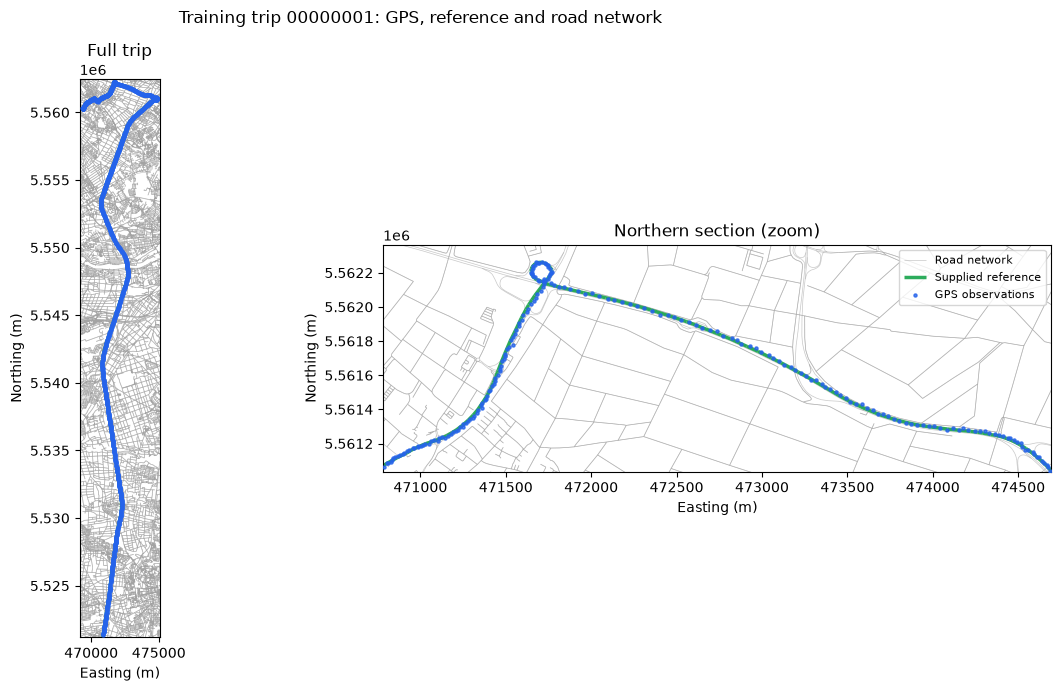

In [5]:
# Draw the supplied GPS points, road network and reference route.
# The zoomed panel makes nearby roads easier to see.
from matplotlib.collections import LineCollection
make_map(trip, OUT/'maps'/'training_trip_00000001.html')
xy = project(road.transformer, track[['longitude','latitude']].to_numpy())
road_segments = road.xy[arcs]
reference_segments = road_segments[route]
# A second view zooms into the upper part of this long north-south trip.
overview_bounds = (xy.min(axis=0)-200, xy.max(axis=0)+200)
focus = xy[xy[:, 1] >= np.quantile(xy[:, 1], .85)]
focus_bounds = (focus.min(axis=0)-100, focus.max(axis=0)+100)
fig, axes = plt.subplots(1, 2, figsize=(13, 7))
for ax, bounds, title in zip(axes, [overview_bounds, focus_bounds],
                             ['Full trip', 'Northern section (zoom)']):
    lower, upper = bounds
    visible = np.all(road_segments.max(axis=1) >= lower, axis=1) & np.all(road_segments.min(axis=1) <= upper, axis=1)
    ax.add_collection(LineCollection(road_segments[visible], colors='#a3a3a3',
                                   linewidths=.5, alpha=.6, label='Road network'))
    ax.add_collection(LineCollection(reference_segments, colors='#16a34a',
                                   linewidths=2.5, alpha=.9, label='Supplied reference'))
    points = np.all((xy >= lower) & (xy <= upper), axis=1)
    ax.scatter(xy[points, 0], xy[points, 1], s=5, color='#2563eb',
               alpha=.8, label='GPS observations', zorder=3)
    ax.set(xlim=(lower[0], upper[0]), ylim=(lower[1], upper[1]),
           aspect='equal', title=title, xlabel='Easting (m)', ylabel='Northing (m)')
axes[1].legend(loc='best', fontsize=8)
fig.suptitle(f'Training trip {trip.name}: GPS, reference and road network')
fig.tight_layout()
fig.savefig(OUT/'figures'/'training_trip_00000001.png', dpi=170, bbox_inches='tight')
plt.show()

## Export all permitted trips
Each trip receives candidates.npz, targets.npz, observations.csv.gz, labels.csv.gz and metadata.json. Candidate misses and weak-label coverage remain in the summary. No evaluator data is accessed.

In [6]:
# Process every permitted trip and save its features and separate labels.
summary = process_dataset(DATA, OUT / "processed", CONFIG)
summary_columns = [
    "clean_observations", "candidate_rows", "no_candidate_observations",
    "usable_label_observations", "reference_candidate_misses", "fit_rows",
]
display(summary.groupby("partition")[summary_columns].sum())
summary.to_csv(OUT / "processing_summary.csv", index=False)


train: 10/80 trips processed


train: 20/80 trips processed


train: 30/80 trips processed


train: 40/80 trips processed


train: 50/80 trips processed


train: 60/80 trips processed


train: 70/80 trips processed


train: 80/80 trips processed


student_test: 10/10 trips processed


,clean_observations,candidate_rows,no_candidate_observations,usable_label_observations,reference_candidate_misses,fit_rows
partition,,,,,,
student_test,19156,130903,0,17643,36,118582
train,207731,1354225,1413,153051,968,1017839


## Trip-level cross-validation
All rows from a trip remain in one fold. Learned scaling must be fitted inside the training folds in the later model notebook.

In [7]:
# Give each whole training trip one validation fold.
# This keeps GPS points from the same trip together during later model tests.
trip_ids = np.array([trip.name for trip in discover_trips(DATA, "train")])
fold_for_trip = np.empty(len(trip_ids), dtype=int)
splitter = KFold(n_splits=5, shuffle=True, random_state=42)

for fold_number, (_, validation_rows) in enumerate(splitter.split(trip_ids)):
    fold_for_trip[validation_rows] = fold_number

fold_table = pd.DataFrame({
    "trip_id": trip_ids,
    "validation_fold": fold_for_trip,
})
fold_table.to_csv(OUT / "training_folds.csv", index=False)
print("Wrote five trip-level folds.")


Wrote five trip-level folds.


Next stages: train and compare five models, perform Bayesian tuning, then implement HMM/Viterbi, API and UI. Pointwise metrics must be described as agreement with derived weak labels.